# Givers, Takers and the Shape of a City

- We model a **city** as a network of citizens who are either **givers** (cooperative strategies) or **takers** (exploitative ones), playing the **Iterated Prisoner's Dilemma** with the people they actually meet.
- We build the city in **five steps (S1 to S5)**, adding one mechanism at a time: from a well-mixed crowd, to a fixed network, to ties that fade, to partners chosen by proximity, habit and status, to a city that replaces the relationships it loses.
- We sweep the **share of givers** from 0 to 1 in every step and ask what happens to **prosperity** (wealth per person), **inequality** (Gini coefficient) and **structure** (who ends up connected to whom).
- What we find: more givers always make a city richer, but the richest cities are not the most equal. Inequality peaks in mixed cities, and it stays high on a network with hubs, where the citizens everyone wants to meet capture the gains.

## Background and Goal

**The phenomenon:** communities of similar size and resources end up in very different places: some generate a lot of wealth and spread it widely, others generate less and concentrate it. Cooperation is part of the story, but its payoff is strongly context-dependent: across 83 studies and 957 estimates, the average effect of social capital on growth is close to zero, with large positive and negative effects in different settings [1]. What seems to matter is *who* is connected to whom: cross-class friendships predict upward mobility, while tight-knit cohesion does not [2].

**Why an agent-based model:** prosperity, inequality and social segregation are outcomes nobody in a city chooses. They emerge from many local interactions, each of which is simple to state. That is the case for simulating individual agents and their interactions rather than writing an equation for the aggregate [3].

**What is uncertain:** whether cooperation also makes a society more equal is contested. Network-game models find inequality falling as cooperation rises [4], [5]; laboratory networks with clustering produce more inequality and rich-poor segregation [6]; and making wealth visible amplifies initial advantage [7].

**Research question:**

> In simulated cities that differ in their mix of cooperative and exploitative agents, what patterns emerge in prosperity, in how that prosperity is distributed, and in who ends up connected to whom?

**Hypotheses:**

| # | Hypothesis | What would refute it |
|---|---|---|
| **H1** | **Prosperity threshold:** wealth per person rises with the share of givers, non-linearly, with a share below which cooperation cannot get established. | Wealth is a straight line in the giver share. |
| **H2** | **Prosperity and equality decouple:** inequality does not simply fall as givers increase; it flattens or rises in the richest cities, because cooperation relies on clusters [8], [9] and popular citizens attract more of the surplus. | Inequality falls steadily with the giver share on every network. |
| **H3** | **Emergent segregation:** givers end up tied to givers and takers are pushed to the edges, with no rule telling anyone to avoid anyone. | Class assortativity stays flat and takers keep giver-level ties. |
| **H4** | **The poverty trap is equal:** taker-dominated cities are poor but not unequal, so median wealth separates good cities from bad better than inequality does. | Taker-dominated cities are markedly unequal. |

H2 runs against the existing model results, so either answer is informative.

## The Model

### Citizens and the game

Every agent keeps one fixed strategy for the whole run. Each meeting is one round of the Prisoner's Dilemma, with the payoffs `(T, R, P, S) = (5, 3, 1, 0)` used in [3, Ch. 12]:

| | Opponent cooperates | Opponent defects |
|---|---|---|
| **You cooperate** | 3 | 0 |
| **You defect** | 5 | 1 |

Because `2R = 6 > T + S = 5 > 2P = 2`, a cooperating pair **creates** more wealth than an exploitative pair, which creates more than a mutually defecting pair. Wealth is created by interaction, not moved between agents, so a city's total wealth reports how its citizens have treated each other.

| Strategy | Behaviour | Class |
|---|---|---|
| **AllC** | Always cooperates. | Giver |
| **TFT** | Cooperates first, then copies the partner's last move. | Giver |
| **GTFT** | TFT, but forgives a defection with probability 0.1. | Giver |
| **TF2T** | Defects only after two defections in a row. | Giver |
| **Grudger** | Cooperates until the first defection, then defects forever. | Giver |
| **Pavlov** | Repeats its last move if it scored well, switches if not. | Giver |
| **AllD** | Always defects. | Taker |
| **Random** | Cooperates with probability 0.5. | Taker |

The **giver fraction** `f` is the share of agents drawn from the giver class; the mix within each class is fixed, so one number describes a city's population.

### Terms

- **Tie:** an acquaintance relationship, with a **strength** that grows with use and fades without it. A tie is not a meeting: having a tie means these two know each other.
- **Meeting:** one interaction in one round, which is one game of the Prisoner's Dilemma. Each agent starts one meeting per round and may be chosen by others.
- **Tie capacity:** the number of ties an agent may hold, fixed at its degree in the starting network, so a city keeps its degree distribution as ties break and form.
- **Popularity rating:** a bounded, slow-moving score of how cooperative and well-connected an agent has been. It is a coarse public signal, not perfect information.
- **Giver-dominated / taker-dominated:** cities with `f >= 0.7` and `f <= 0.3`.

### One round

```
for each round t in 1..T:
    1. every agent picks a partner        (proximity x habit x popularity)
    2. each pair plays one game           (each strategy sees its history with that partner)
    3. payoffs are added to wealth
    4. ties used this round get stronger
    5. unused ties decay with time since contact
    6. ties below the severance threshold break
    7. agents with spare capacity form new ties (friends of friends)
    8. popularity ratings update
```

Updating is synchronous: every choice in a round uses the state at the start of that round.

### The three rules that decide behaviour

Everything the model does comes from three rules. Each one is given in symbols, then in plain
words, with the numbers we actually use.

**Rule 1: who meets whom**

Each week every citizen picks one person to meet, and not at random. Every possible partner `j`
gets a score, and the chance of picking them is their score divided by the total of all the
scores:

$$ s_{ij} = \underbrace{(w_{ij} + \varepsilon)^{\beta}}_{\text{habit}} \times \underbrace{R_j^{\gamma}}_{\text{standing}} \times \underbrace{d_{ij}^{-\lambda}}_{\text{closeness}} $$

- **Habit**, $w_{ij}$: how strong the relationship between `i` and `j` already is. Someone you
  see often scores higher. The small amount $\varepsilon = 0.1$ is added to everybody's score so
  that a person you have never met still has some chance of being picked. Without it no new
  relationship could ever start.
- **Standing**, $R_j$: how popular `j` is, a number between 0.1 and 1 defined in rule 3.
- **Closeness**, $d_{ij}$: how many handshakes away `j` is. A neighbour is 1 away and scores
  $1^{-1} = 1$. A friend of a friend is 2 away and scores $2^{-1} = 0.5$, so is half as likely,
  everything else being equal. We never look further than 3 handshakes. This $1/d$ shape is how
  the chance of a real social tie falls off with distance [10].
- The exponents $\beta$, $\gamma$ and $\lambda$ say how much each of the three counts. All are 1
  here, so the three count equally, and setting one to 0 switches that influence off. That is how
  the five steps below are built.
- **A worked example:** a well-liked neighbour you already see often ($w = 5$, $R = 0.9$,
  $d = 1$) scores $5.1 \times 0.9 \times 1 = 4.6$. A poorly rated stranger two handshakes away
  ($w = 0$, $R = 0.2$, $d = 2$) scores $0.1 \times 0.2 \times 0.5 = 0.01$. The neighbour is about
  450 times likelier to be chosen.
- Other people are choosing too, so a citizen can be picked by several in one week. The number of
  meetings anyone can **receive** is capped at $c_{max} = 4$ a week: attention is finite, and
  without a cap the most popular person soaks up an unlimited share of the city's meetings.

**Rule 2: relationships strengthen, fade and break**

- Every meeting adds $\delta = 1$ to the strength of that relationship.
- Strength fades with the time since the last meeting, $w \times e^{-\alpha \Delta t}$, at
  $\alpha = 0.05$ per week. This is **neglect, not punishment**: a relationship fades because it
  goes unused, whatever happened the last time the two met [11].
- When strength falls below $\theta = 0.1$ the relationship is dropped. Starting from a single
  meeting, that takes $\ln(10) / 0.05 \approx 46$ weeks without contact.
- A relationship is judged on **its own** strength, not against a better offer. Judging by
  comparison would freeze the city: someone you have never met has strength near 0, so they could
  never beat someone you already know.

**Rule 3: popularity, meaning how visible and well regarded someone is**

Each citizen carries a single number, their rating, standing for how good they are to meet. It is
built from two things any real citizen could notice:

- **How cooperative they have been lately**, $\kappa_j$: the share of their recent moves that
  were cooperative. It is a slow-moving average, so one bad week does not destroy a reputation
  and one good week does not make one.
- **How connected they are**, $s_j$: the total strength of all their relationships, divided by
  the largest total in the city. The best-connected citizen scores 1 and a recluse scores near 0.

$$ R_j = R_{min} + (R_{max} - R_{min}) \times \kappa_j \times s_j = 0.1 + 0.9 \times \kappa_j \times s_j $$

The two are multiplied, so a citizen needs both: a cooperative hermit and a well-connected
defector both end up with a low rating. The answer is then squeezed into the range 0.1 to 1. The
floor of 0.1 matters, because it means nobody is ever literally unreachable, only unlikely to be
chosen.

This rating is the only thing a citizen knows about someone they have not met, and it is kept
coarse and slow: citizens respond to a rough social signal, not to perfect information about each
other. No rule anywhere says to avoid a taker. If takers end up
isolated, it is only because defecting lowers their rating, a lower rating means being chosen
less often, and a relationship nobody uses fades and is dropped.

## Scenarios: What We Run and What to Expect

Each step adds one mechanism to the one before it. Every step chooses partners with the same sampling rule, so **each step reproduces the previous one exactly, with the same seed, when its new mechanism is switched off**. That is the main correctness check, and it means any change in behaviour can be attributed to the mechanism just added.

| ID | Network | Who you can meet | Ties | Rewiring | What it represents |
|:--:|---|---|---|:--:|---|
| **S1** | complete | anyone in the city, uniformly | none | n/a | A well-mixed crowd: the mean-field baseline |
| **S2** | Erdős–Rényi | your neighbours, uniformly | permanent | No | Structure alone: repeated local interaction |
| **S3** | Erdős–Rényi | your neighbours, uniformly | decay and severance | No | Neglect: relationships fade without contact |
| **S4** | Erdős–Rényi | anyone within 3 hops, by proximity x habit x popularity | decay and severance | No | Choice: who you meet depends on distance, habit and status |
| **S5** | Erdős–Rényi | as S4 | decay and severance | Yes | The full city: lost relationships are replaced |
| **S5b** | Barabási–Albert | as S4 | decay and severance | Yes | The full city on a scale-free network, which has hubs |

**What to expect, and why:**

- **S1, well-mixed:** takers do well: a taker meets a new partner almost every round, so retaliation rarely lands on the agent that earned it. Wealth should rise with the giver share, and inequality should be low, because nobody has a structural advantage.
- **S2, static network:** repeated meetings with the same neighbours let reciprocal strategies recognise and punish takers, which is network reciprocity [8]. Expect the taker advantage to shrink and inequality to rise above S1, since a citizen's fate now depends on the neighbours they happen to have.
- **S3, ties fade:** with the default decay rate a tie played every few rounds never fades, so expect S3 to look much like S2. Decay cannot tell a giver from a taker here, because partners are still drawn uniformly.
- **S4, chosen partners:** this is where classes should separate. Cooperative agents earn higher ratings, are chosen more often and play more games, so expect givers to pull ahead, inequality to rise, and takers to lose ties.
- **S5, the full city:** refilling severed ties should keep the network in one piece without changing who prospers, since new ties are drawn by the same rule that favoured the same people.
- **S5b, scale-free:** hubs start with many more ties than anyone else and attract more meetings, so expect the highest inequality and the clearest case of prosperity and equality moving apart.

## Protocol and Assumptions

**Runs:**

1. `N = 100` agents per city, `T = 500` rounds. One round is read as a week.
2. **40 seeds** per point, and the giver fraction `f` takes the values 0, 0.2, 0.4, 0.6, 0.8, 1.0.
3. The same seeds are used in every scenario, so differences come from the rules rather than from the draw.
4. Every stochastic step draws from one seeded `numpy` generator passed through the model. There is no global random state, so a run is reproducible from its seed and configuration.
5. Cities start with zero wealth and a uniform small weight on every tie, so nobody begins privileged.

**Measures**, all taken at the end of the run unless stated:

| Measure | Definition |
|---|---|
| **Wealth per person** | Mean accumulated payoff. Prosperity. |
| **Median wealth** | The typical citizen, which falls below the mean when gains concentrate. |
| **Gini coefficient** | Inequality of accumulated wealth: 0 is everyone equal, 1 is one agent holding everything. |
| **Cooperation rate** | Share of all moves that were cooperative, averaged over the last 100 rounds. |
| **Taker payoff gap** | Taker minus giver payoff per game. Positive means exploitation pays. |
| **Class assortativity** | Correlation of class across ties: positive means givers tie to givers, negative means the classes mix. |
| **Realised partners** | Distinct agents an individual actually played in the last 100 rounds. |
| **Noise floor** | Gini of a city where everyone plays the same strategy, so any inequality comes from luck and network position alone. |

**Assumptions:** strategies never change or learn; agents cannot refuse a game; wealth is never spent or lost; and every city is closed, with no birth, death or migration.

## Parameter Reference

Values used in every run below. The model exposes each as a configuration key, and alternatives listed in the right-hand column can be selected without changing code.

| Symbol | Config key | Meaning | Value here | Alternatives available |
|---|---|---|---|---|
| `N` | `population.n_agents` | agents per city | 100 | any |
| `T` | `run.n_rounds` | rounds per run | 500 | any |
| `f` | `population.giver_fraction` | share of givers | 0 to 1, step 0.2 | any |
| `k` | `topology.mean_degree` | mean degree of the starting network | 6 | any |
| | `topology.name` | starting network | `erdos_renyi`, `barabasi_albert` | `watts_strogatz`, `complete` |
| `(T,R,P,S)` | `game.payoff` | payoff matrix | (5, 3, 1, 0) | any ordering |
| `rho` | `game.rho` | resource density, a payoff multiplier | 1.0 | any |
| `c` | `game.subsistence_cost` | wealth deducted per agent per round | 0.0 | any |
| `nu` | `game.noise` | chance an intended move is flipped | 0.0 | any |
| `B` | `encounter.initiated` | meetings each agent starts per round | 1 | any |
| `c_max` | `encounter.max_received` | cap on meetings received per round | 4 | any, or no cap |
| `d_max` | `encounter.d_max` | furthest candidate partner, in hops | 3 | any |
| `lambda` | `encounter.distance_exponent` | pull of proximity | 1.0 | any; rank-based form |
| `beta` | `encounter.weight_exponent` | pull of habit | 1.0 | any |
| `gamma` | `encounter.popularity_exponent` | pull of status | 1.0 | any |
| `eps` | `encounter.eps` | offset allowing contact without a tie | 0.1 | any |
| `alpha` | `ties.decay_rate` | tie decay per round | 0.05 | any |
| `theta` | `ties.severance_threshold` | ties below this break | 0.1 | any |
| `delta` | `ties.reinforcement` | weight added per meeting | 1.0 | any |
| `R_min`, `R_max` | `popularity.r_min`, `r_max` | rating bounds | 0.1, 1.0 | any |
| `eta` | `popularity.smoothing` | smoothing of the cooperation average | 0.1 | any |
| | `popularity.rule` | what the rating rewards | `behaviour_x_strength` | `behaviour`, `strength` |
| | `ties.severance_rule` | how ties break | `absolute` | `none` |
| | `rewiring.rule` | how freed capacity is refilled | `local_refill` | `none` |
| `n_s` | seeds per point | repeats | 8 | any |

The decay rate, threshold, cap and offset were fixed by a calibration sweep that asked which settings keep a 50/50 city away from the extremes of total collapse and total cooperation.

In [1]:
# One BLAS thread per process: the sweep runs whole cities in parallel, so threads underneath
# them only contend. This must happen before numpy is imported.
import os
for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_var, "1")

from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "source").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from source import metrics
from source.presets import stage
from source.simulation import Simulation
from utilities import plotting as P
from utilities import runs as R
from utilities.checks import check, same_run, trace

P.use_style()
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | networkx {nx.__version__} | pandas {pd.__version__}")

python 3.12.3 | numpy 2.5.3 | networkx 3.7 | pandas 3.0.6


## Checks

Before reading any result, each step must reproduce the step before it when its new mechanism is switched off, and the bookkeeping must hold. These run on small, short cities.

In [2]:
small = {"population.n_agents": 60, "run.n_rounds": 120}

# S3 without decay or severance is S2; S5 without severance is S4. Identical agent by agent.
s2 = trace(Simulation(stage("M1", **small), root_seed=5, repeat=0))
s3_off = trace(Simulation(stage("M2", **{**small, "ties.decay_rate": 0.0, "ties.severance_threshold": 0.0}), root_seed=5, repeat=0))
check(same_run(s2, s3_off), "S3 with no decay and no severance reproduces S2 exactly")

s4 = trace(Simulation(stage("M3", **{**small, "ties.severance_threshold": 0.0}), root_seed=8, repeat=0))
s5_off = trace(Simulation(stage("M4", **{**small, "ties.severance_threshold": 0.0}), root_seed=8, repeat=0))
check(same_run(s4, s5_off), "S5 with no severance reproduces S4 exactly")

sim = Simulation(stage("M4", **small), root_seed=8, repeat=1, instruments=("core",))
out = sim.run().outputs["core"]
s = sim.state
check(np.isclose(s.wealth.sum(), s.payoff_total.sum()), "every unit of wealth comes from a game payoff")
check((s.degree() <= s.capacity).all(), "no agent holds more ties than its capacity")
check(np.array_equal(s.adjacency, s.adjacency.T) and not s.adjacency.diagonal().any(), "ties are mutual, and nobody is tied to themselves")
check(out["max_received"].max() <= stage("M4").encounter.max_received, "no agent is met more often than the cap allows")

PASS  S3 with no decay and no severance reproduces S2 exactly


PASS  S5 with no severance reproduces S4 exactly
PASS  every unit of wealth comes from a game payoff
PASS  no agent holds more ties than its capacity
PASS  ties are mutual, and nobody is tied to themselves
PASS  no agent is met more often than the cap allows


## One City, Watched for 500 Weeks

A single mixed city (`f = 0.5`) on the full model, to see what the rules produce before comparing scenarios. Node colour is strategy, node size is wealth, and edge width is tie strength.

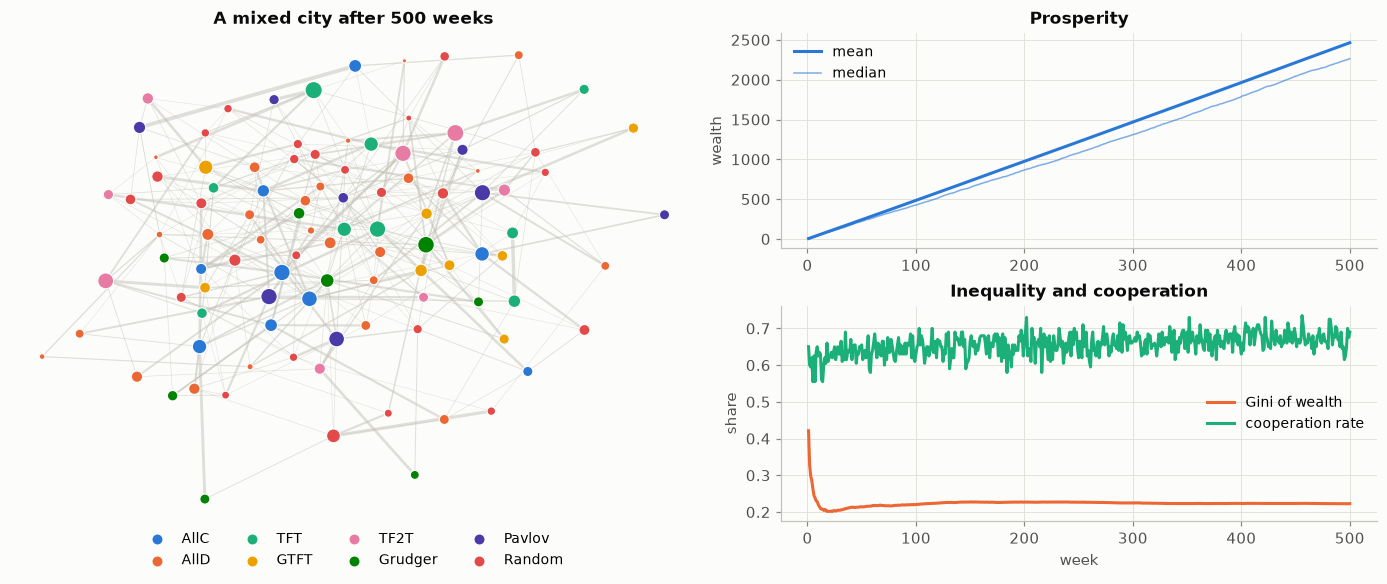

mean wealth 2464 | median 2264 | Gini 0.223
givers 3065 | takers 1863


In [3]:
from utilities.network_draw import draw_snapshot, layout, strategy_legend

city = Simulation(stage("M4", **{"population.n_agents": 100, "run.n_rounds": 500, "population.giver_fraction": 0.5}),
                  root_seed=R.DEFAULT_SEED, repeat=0, instruments=("core", "snapshot"))
result = city.run()
core, snap = result.outputs["core"], result.outputs["snapshot"]

fig = plt.figure(figsize=(12.5, 5.2))
grid = fig.add_gridspec(2, 2, width_ratios=[1.15, 1])
ax_net = fig.add_subplot(grid[:, 0])
draw_snapshot(ax_net, snap, layout(snap["adjacency"], seed=7), title="A mixed city after 500 weeks")
strategy_legend(ax_net)

ax_top, ax_bottom = fig.add_subplot(grid[0, 1]), fig.add_subplot(grid[1, 1])
weeks = np.arange(1, len(core["gini"]) + 1)
ax_top.plot(weeks, core["mean_wealth"], color=P.SERIES[0], label="mean")
ax_top.plot(weeks, core["median_wealth"], color=P.SERIES[0], linewidth=1, alpha=0.6, label="median")
ax_top.set(ylabel="wealth", title="Prosperity")
ax_top.legend(loc="upper left")
ax_bottom.plot(weeks, core["gini"], color=P.SERIES[1], label="Gini of wealth")
ax_bottom.plot(weeks, core["coop_rate"], color=P.SERIES[2], label="cooperation rate")
ax_bottom.set(xlabel="week", ylabel="share", title="Inequality and cooperation")
ax_bottom.legend(loc="center right")
plt.show()

wealth = city.state.wealth
print(f"mean wealth {wealth.mean():.0f} | median {np.median(wealth):.0f} | Gini {metrics.gini(wealth):.3f}")
print(f"givers {wealth[city.state.giver].mean():.0f} | takers {wealth[~city.state.giver].mean():.0f}")

**What happens:** wealth accumulates steadily and the cooperation rate settles within about 100 weeks. The Gini coefficient spikes early, when a few lucky agents have banked almost everything that exists, then falls and levels off once every citizen has a history. The mean pulls away from the median, which is the signature of gains concentrating on some citizens rather than all.

## Experiment: Sweeping the Mix of Givers and Takers

Every scenario, at six giver fractions, with 40 seeds each: 1,440 cities. Each run takes about a second, and they run in parallel, so the whole sweep takes about five minutes.

In [4]:
SCENARIOS = {
    "S1 well-mixed":     ("M0", {}),
    "S2 static network": ("M1", {}),
    "S3 ties fade":      ("M2", {}),
    "S4 chosen partners": ("M3", {}),
    "S5 full city":      ("M4", {}),
    "S5b scale-free":    ("M4", {"topology.name": "barabasi_albert"}),
}
FRACTIONS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
SETTINGS = {"population.n_agents": 100, "run.n_rounds": 500}
# Every seed count in the notebook comes from here, including the figure captions.
N_SEEDS = 40

sweep = R.sweep(SCENARIOS, FRACTIONS, n_seeds=N_SEEDS, timeseries=True, **SETTINGS)
runs = sweep.runs
print(f"{len(runs)} cities: {runs['scenario'].nunique()} scenarios x {len(FRACTIONS)} giver fractions x {N_SEEDS} seeds")
print(f"histories kept: {len(sweep.core):,} core rows, {len(sweep.structure):,} structure rows")
runs.head(3)

1440 cities: 6 scenarios x 6 giver fractions x 40 seeds
histories kept: 144,000 core rows, 73,440 structure rows


,scenario,repeat,giver_fraction,topology,mean_wealth,median_wealth,total_wealth,mean_income,gini,top10_share,...,realised_degree_taker,isolated_giver,isolated_taker,clustering,clustering_giver,clustering_taker,transitivity,mean_path_length,n_components,assortativity_slope
0,S1 well-mixed,0,0.0,complete,1692.62,1686.0,169262.0,3.3980,0.105469,0.124824,...,39.66,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN
1,S1 well-mixed,1,0.0,complete,1689.42,1642.5,168942.0,3.3882,0.106915,0.124552,...,40.02,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN
2,S1 well-mixed,2,0.0,complete,1682.70,1671.0,168270.0,3.3504,0.108695,0.126351,...,39.94,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,NaN


### Prosperity, Inequality and Cooperation

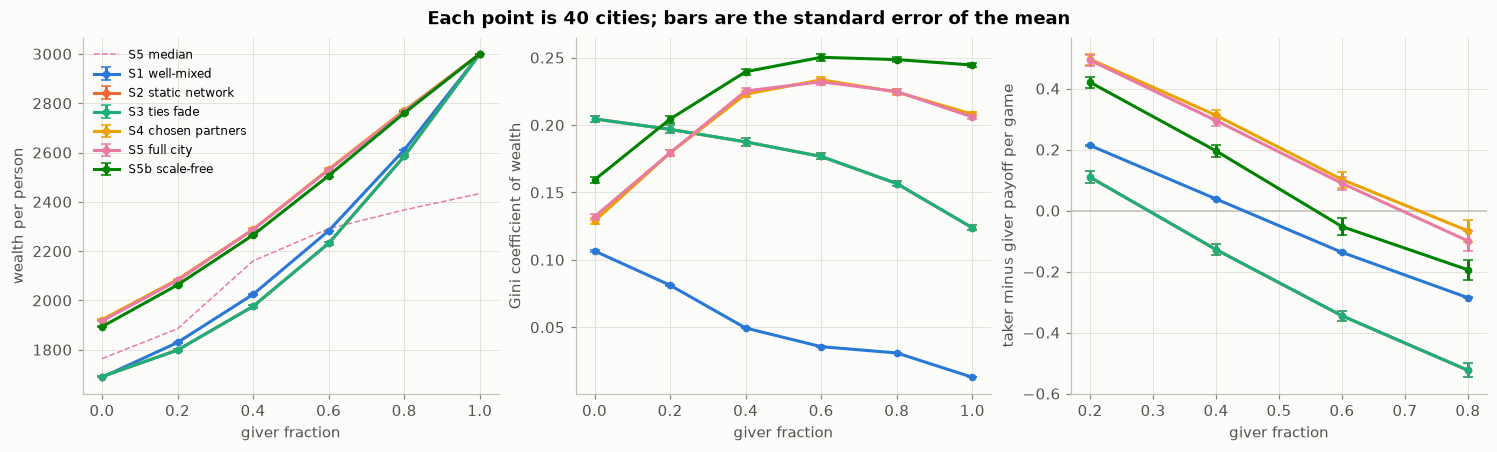

gini                                 \
scenario       S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                
0.0                    0.107             0.205        0.205   
0.2                    0.081             0.197        0.197   
0.4                    0.049             0.187        0.187   
0.6                    0.036             0.177        0.177   
0.8                    0.031             0.157        0.157   
1.0                    0.013             0.124        0.124   

                                                                mean_wealth  \
scenario       S4 chosen partners S5 full city S5b scale-free S1 well-mixed   
giver_fraction                                                                
0.0                         0.129        0.132          0.159      1688.066   
0.2                         0.179        0.179          0.204      1829.308   
0.4                         0.223        0.225          0.240      2024.529   
0.6                         0.234        0.232          0.250      2282.577   
0.8                         0.224        0.225          0.249      2610.684   
1.0                         0.208        0.206          0.244      3000.000   

                                                                               \
scenario       S2 static network S3 ties fade S4 chosen partners S5 full city   
giver_fraction                                                                  
0.0                     1690.898     1690.898           1921.790     1916.346   
0.2                     1798.563     1798.563           2084.552     2081.028   
0.4                     1975.890     1975.890           2288.013     2287.404   
0.6                     2231.592     2231.592           2531.958     2528.970   
0.8                     2584.798     2584.798           2770.458     2767.136   
1.0                     3000.000     3000.000           3000.000     3000.000   

                               
scenario       S5b scale-free  
giver_fraction                 
0.0                  1893.470  
0.2                  2062.800  
0.4                  2265.332  
0.6                  2506.095  
0.8                  2759.826  
1.0                  3000.000

In [5]:
means = R.cell_means(runs, ["mean_wealth", "median_wealth", "gini", "coop_rate", "payoff_gap"])
colours = dict(zip(SCENARIOS, P.SERIES))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))
panels = [("mean_wealth", "wealth per person"), ("gini", "Gini coefficient of wealth"),
          ("payoff_gap", "taker minus giver payoff per game")]
for ax, (metric, label) in zip(axes, panels):
    for name in SCENARIOS:
        rows = means[means["scenario"] == name]
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"],
                    color=colours[name], marker="o", markersize=4, capsize=3, label=name)
    ax.set(xlabel="giver fraction", ylabel=label)
axes[0].plot(means[means["scenario"] == "S5 full city"]["giver_fraction"],
             means[means["scenario"] == "S5 full city"]["median_wealth"],
             color=colours["S5 full city"], linewidth=1, linestyle="--", label="S5 median")
axes[2].axhline(0, color=P.AXIS, linewidth=1)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Each point is {N_SEEDS} cities; bars are the standard error of the mean", fontweight="bold")
plt.show()

means.pivot_table(index="giver_fraction", columns="scenario", values=["mean_wealth", "gini"]).round(3)

### Who Ends Up Connected to Whom

S2 and S3 produce identical cities, so only one of their two lines is visible below.

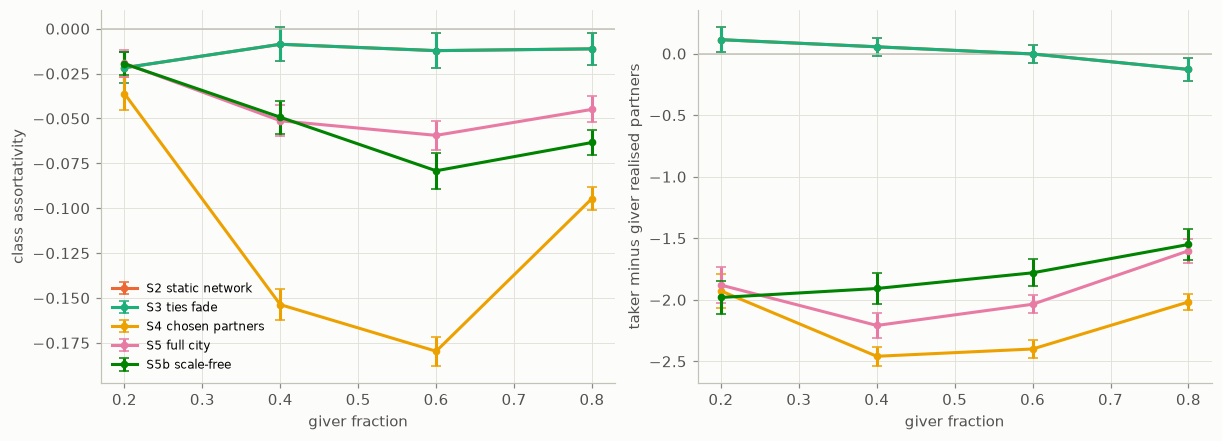

assortativity_class                                 \
scenario             S1 well-mixed S2 static network S3 ties fade   
giver_fraction                                                      
0.2                          -0.01            -0.022       -0.022   
0.4                          -0.01            -0.009       -0.009   
0.6                          -0.01            -0.012       -0.012   
0.8                          -0.01            -0.011       -0.011   

                                                                partner_gap  \
scenario       S4 chosen partners S5 full city S5b scale-free S1 well-mixed   
giver_fraction                                                                
0.2                        -0.036       -0.019         -0.020        -0.040   
0.4                        -0.154       -0.051         -0.049        -0.100   
0.6                        -0.180       -0.059         -0.079         0.116   
0.8                        -0.095       -0.045         -0.063         0.162   

                                                                               \
scenario       S2 static network S3 ties fade S4 chosen partners S5 full city   
giver_fraction                                                                  
0.2                        0.113        0.113             -1.928       -1.880   
0.4                        0.055        0.055             -2.459       -2.209   
0.6                       -0.003       -0.003             -2.400       -2.036   
0.8                       -0.128       -0.128             -2.018       -1.602   

                               
scenario       S5b scale-free  
giver_fraction                 
0.2                    -1.981  
0.4                    -1.908  
0.6                    -1.781  
0.8                    -1.551

In [6]:
structure = runs.assign(partner_gap=runs["realised_degree_taker"] - runs["realised_degree_giver"],
                        weight_gap=runs["weight_taker"] - runs["weight_giver"])
mixed = structure[structure["giver_fraction"].between(0.15, 0.85)]
struct_means = R.cell_means(mixed, ["assortativity_class", "partner_gap", "weight_gap"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, (metric, label) in zip(axes, [("assortativity_class", "class assortativity"),
                                      ("partner_gap", "taker minus giver realised partners")]):
    for name in ["S2 static network", "S3 ties fade", "S4 chosen partners", "S5 full city", "S5b scale-free"]:
        rows = struct_means[struct_means["scenario"] == name]
        ax.errorbar(rows["giver_fraction"], rows[metric], yerr=rows[f"{metric}_se"],
                    color=colours[name], marker="o", markersize=4, capsize=3, label=name)
    ax.axhline(0, color=P.AXIS, linewidth=1)
    ax.set(xlabel="giver fraction", ylabel=label)
axes[0].legend(fontsize=8, loc="lower left")
plt.show()

struct_means.pivot_table(index="giver_fraction", columns="scenario",
                         values=["assortativity_class", "partner_gap"]).round(3)

### How Unequal Is a City That Cannot Be Unfair?

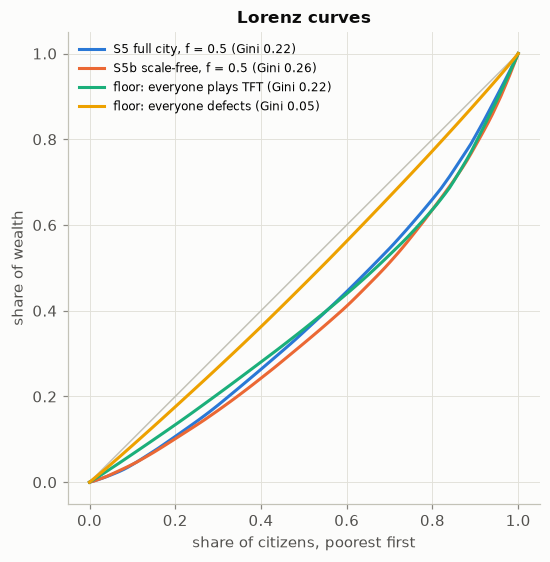

In [7]:
tft_only = {"population.giver_fraction": 1.0, "population.giver_composition": {"tft": 1.0}}
alld_only = {"population.giver_fraction": 0.0, "population.taker_composition": {"alld": 1.0}}
lorenz_curves, floor_gini = {}, {}
for label, base, overrides in [("S5 full city, f = 0.5", "M4", {"population.giver_fraction": 0.5}),
                               ("S5b scale-free, f = 0.5", "M4", {"population.giver_fraction": 0.5, "topology.name": "barabasi_albert"}),
                               ("floor: everyone plays TFT", "M4", tft_only),
                               ("floor: everyone defects", "M4", alld_only)]:
    sim = Simulation(stage(base, **{**SETTINGS, **overrides}), root_seed=R.DEFAULT_SEED, repeat=0, instruments=("core",))
    sim.run()
    lorenz_curves[label] = metrics.lorenz(sim.state.wealth)
    floor_gini[label] = metrics.gini(sim.state.wealth)

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color=P.AXIS, linewidth=1)
for (label, (p, l)), colour in zip(lorenz_curves.items(), P.SERIES):
    ax.plot(p, l, color=colour, label=f"{label} (Gini {floor_gini[label]:.2f})")
ax.set(xlabel="share of citizens, poorest first", ylabel="share of wealth", title="Lorenz curves")
ax.legend(fontsize=8, loc="upper left")
ax.set_aspect("equal")
plt.show()

**What this shows:** a city where every agent plays TFT, so no game is ever exploited, is just as unequal as the mixed city (Gini 0.22 in both). We did not expect that. A city where everyone defects is far more equal, because there is almost nothing to be unequal about. So the inequality in a mixed city is not the visible mark of exploitation: it is **positional**, produced by who gets met and how often. What the mix of givers and takers changes is *who* ends up poor, and how much wealth exists to divide. What changes the level of inequality is the network: the scale-free city, with its hubs, sits above both.

## Results and Discussion

### What the plots show

**Prosperity (H1):** wealth per person rises with the giver share in every scenario, from roughly 1,700 to 3,000. The rise is not a straight line: it is shallow while takers dominate and steeper once givers are common, because an extra giver only creates surplus when there is another giver to meet. In the well-mixed city (S1), inequality is the lowest of any scenario at every mix, since meeting everyone with equal probability gives no citizen a structural edge.

**Structure changes who wins (S1 to S2):** putting the same population on a fixed network raises inequality sharply and turns the taker payoff advantage negative at moderate giver shares: with repeated meetings, reciprocal strategies punish the takers they can recognise. This is network reciprocity, and it is visible as the gap between the S1 and S2 curves.

**Neglect alone has no effect here (S2 to S3):** not one tie breaks in any S3 city: with about six neighbours and a meeting every week, a tie is used long before it could decay past the threshold. Wealth, cooperation and inequality are therefore identical to S2, run for run; only the tie strengths differ, because decay keeps them bounded instead of letting them accumulate indefinitely. Decay also cannot tell a giver from a taker while partners are drawn uniformly.

**Choice separates the classes (S3 to S4):** once meetings depend on proximity, habit and popularity, inequality rises by about a fifth at `f = 0.4` and by about 40% at `f = 0.6` and above, and takers end with about two fewer realised partners than givers out of roughly ten. Most of the inequality in the full model appears at this step.

**Rewiring repairs without redistributing (S4 to S5):** refilling severed ties leaves wealth, cooperation and inequality within a few percent of S4, because new ties are drawn by the same rule that already favoured the same citizens. It does halve the class disassortativity, since a refilled tie is a fresh draw rather than a surviving habit.

**Hubs concentrate the gains (S5b):** on the scale-free network inequality is the highest of any scenario and stays high in giver-dominated cities, where the other networks are becoming more equal again.

### Why these patterns make sense

1. **Cooperation is a joint product:** two givers create six units of wealth; a giver and a taker create five, most of it going to the taker; two takers create two. Prosperity therefore tracks the *rate of giver-giver meetings*, which grows faster than the giver share itself. That is the threshold in H1.

2. **Inequality needs a mechanism, and here it is access:** in the well-mixed city everyone meets everyone, and inequality stays near the noise floor. Adding a network, then habit, then status, each narrows who a citizen can reach, and each raises inequality. The gains of cooperation flow to whoever is met most.

3. **Takers are not shunned, they are dropped by each other:** class assortativity is negative, not positive: the popularity rating points everyone, takers included, towards cooperative givers, and givers cannot refuse. Ties between two takers are the ones nobody uses, so they decay and break. Takers end up clinging to the givers they exploit, with fewer partners and weaker ties.

4. **The richest cities are not the most equal:** inequality peaks in mixed cities, where both classes are present and the gap between them is widest. Whether it falls again depends on the network: on a random network it does, as takers disappear; on a scale-free network hubs keep collecting meetings, so it stays high.

## Hypothesis Check

Each hypothesis is tested on the full-city scenario (S5) with the decision rules fixed before the runs: a two-segment fit against a straight line for H1 [12], [13]; percentile bootstrap intervals over seeds for the rest [14].

In [8]:
from utilities import stats as S

full = runs[runs["scenario"] == "S5 full city"].rename(columns={"giver_fraction": "population.giver_fraction"})
# A fresh stream per test, so each verdict depends only on the runs and its own seed.
h1 = S.h1_threshold(full, rng=np.random.default_rng(1))
h2 = S.h2_decoupling(full, rng=np.random.default_rng(2))
h3 = S.h3_segregation(full, fractions=FRACTIONS[1:-1], rng=np.random.default_rng(3))
h4 = S.h4_equal_poverty(full, rng=np.random.default_rng(4))

pd.DataFrame([
    {"hypothesis": "H1 prosperity threshold", "test": "two-segment fit beats a line, steeper above the break",
     "result": f"BIC difference {h1['delta_bic']:.0f}, break at f = {h1['break']:.2f}", "verdict": h1["verdict"]},
    {"hypothesis": "H2 prosperity and equality decouple", "test": "Gini and wealth rise together above f = 0.5",
     "result": f"Spearman(f, Gini) = {h2['spearman']:.2f}", "verdict": h2["verdict"]},
    {"hypothesis": "H3 emergent segregation", "test": "assortativity rises; takers keep fewer, weaker ties",
     "result": f"assortativity slope {h3['slope'][0]:.1e}, partner gap {h3['degree_gap'][0]:.2f}, weight gap {h3['weight_gap'][0]:.2f}",
     "verdict": h3["verdict"]},
    {"hypothesis": "H4 the poverty trap is equal", "test": "taker cities poorer, not more unequal",
     "result": f"median wealth gap {h4['median_gap'][0]:.0f}, Gini gap {h4['gini_gap'][0]:.3f}", "verdict": h4["verdict"]},
]).set_index("hypothesis")

,test,result,verdict
hypothesis,,,
H1 prosperity threshold,"two-segment fit beats a line, steeper above th...","BIC difference 211, break at f = 0.28",supported
H2 prosperity and equality decouple,Gini and wealth rise together above f = 0.5,"Spearman(f, Gini) = 0.55",inconclusive
H3 emergent segregation,"assortativity rises; takers keep fewer, weaker...","assortativity slope -6.8e-06, partner gap -1.9...",inconclusive
H4 the poverty trap is equal,"taker cities poorer, not more unequal","median wealth gap -576, Gini gap -0.060",supported


**Reading the verdicts:** H1 and H4 are decided, and the two that remain inconclusive are inconclusive for quite different reasons. Both are worth separating, because at 40 seeds neither is a sample-size problem any more.

- **H1 is supported:** the two-segment fit beats a straight line decisively (BIC difference 211), and the bend sits at a giver share of 0.28, well below a 50/50 mix.
- **H2 is inconclusive, and the extra seeds show this is not for want of resolution:** inequality is *hump-shaped* in the giver share, not monotone in either direction. The Gini climbs steeply while takers dominate (+0.047 and +0.046 over the first two steps), flattens through the middle (+0.007 from 0.4 to 0.6), then *falls* at the top (-0.007 from 0.6 to 0.8 and -0.019 from 0.8 to 1.0), peaking at f = 0.6. H2's supporting criterion asks inequality and wealth to rise **together** above f = 0.5, and they do not: wealth keeps climbing while the Gini turns down. Its refuting criterion asks the Gini to fall with the giver share, and it does not do that either, rising sharply across the bottom half (Spearman 0.55 overall). So H2 is right that prosperity and equality decouple, and wrong about where: the decoupling is in the middle of the range, not at the top.
- **H3 is inconclusive because its two halves disagree:** takers do end up with fewer partners (a gap of -1.9) and weaker ties, but class assortativity is **negative** and flat. With five times the seeds the slope has tightened to -6.8e-06, nearer zero than before rather than further from it, so the decline H3 predicts is not merely unresolved, it is absent. Givers are not clustering together: the exclusion H3 predicted is real; the sorting is not.
- **H4 is supported at 40 seeds, having been inconclusive at 8.** Taker-dominated cities are poorer (median wealth gap -576, interval -595 to -557) and more equal (Gini gap -0.060, interval -0.064 to -0.056), and the giver share now demonstrably explains more of the variation in median wealth than in inequality (difference in eta-squared +0.066, interval +0.044 to +0.092). Only that last interval needed the extra seeds; the two gaps were already clear. This is the one verdict in the project that the seed count changed.

## Extended Analysis

The sweep above reports each city by its final state. That is the right summary for a hypothesis
test, but it discards three things worth looking at: how a city got where it ended up, what each
mechanism contributed on the way, and what the network looked like while it happened.

This section re-reads the same 1,440 runs, and asks four questions:

1. **What converges, and what cannot?** A steady state here is a claim about flows, not stocks.
2. **Where do the scenarios actually diverge?** The ladder adds one mechanism per step, so each
   step's contribution can be measured rather than argued from the curves.
3. **Does the city cluster?** H2 rests on the claim that cooperation depends on clusters, and
   nothing in the model has so far measured one.
4. **Where does inequality come from when nobody is ever exploited?**

### What Converges, and What Cannot

A steady state in this model cannot mean that wealth stops changing. Wealth is a stock that only
accumulates: with no spending and no depreciation, mean wealth rises for as long as the
simulation runs, by construction rather than by result. A convergence test applied to it would
fail forever, however settled the city was.

What can settle is the **flow**: how much income is produced per week, and how unevenly it is
shared. That is why `steady_state` in `source/experiment.py` tests the slope of rolling income
Gini and of mean income rather than of wealth. The figure below is that distinction made visible.

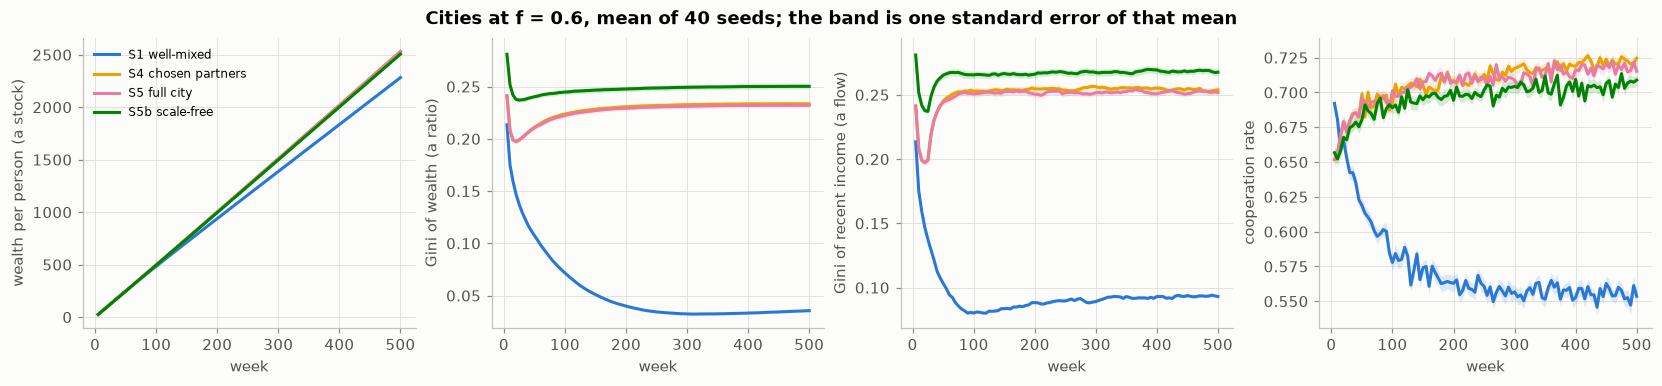

gini        income_gini        mean_wealth          
round                 250    500         250    500         250       500
scenario                                                                 
S1 well-mixed       0.034  0.036       0.090  0.093    1163.952  2282.577
S2 static network   0.177  0.177       0.190  0.190    1117.647  2231.592
S3 ties fade        0.177  0.177       0.190  0.190    1117.647  2231.592
S4 chosen partners  0.232  0.234       0.254  0.254    1255.922  2531.958
S5 full city        0.230  0.232       0.252  0.252    1256.166  2528.970
S5b scale-free      0.249  0.250       0.267  0.268    1247.270  2506.095

In [9]:
LADDER = ["S1 well-mixed", "S2 static network", "S3 ties fade", "S4 chosen partners", "S5 full city"]
SHOWN = ["S1 well-mixed", "S4 chosen partners", "S5 full city", "S5b scale-free"]

# One giver fraction at a time: averaging across the mix would blend cities that differ by design.
mid_core = sweep.core[np.isclose(sweep.core["giver_fraction"], 0.6)]
convergence = R.series_means(mid_core, ["mean_wealth", "gini", "income_gini", "coop_rate"])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
panels = [("mean_wealth", "wealth per person (a stock)"), ("gini", "Gini of wealth (a ratio)"),
          ("income_gini", "Gini of recent income (a flow)"), ("coop_rate", "cooperation rate")]
for ax, (metric, label) in zip(axes, panels):
    P.over_time(ax, convergence, metric, SHOWN, colours, ylabel=label)
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Cities at f = 0.6, mean of {N_SEEDS} seeds; the band is one standard error of that mean",
             fontweight="bold")
plt.show()

convergence[convergence["round"].isin([250, 500])].pivot_table(
    index="scenario", columns="round", values=["mean_wealth", "gini", "income_gini"]).round(3)

**What this shows:** mean wealth doubles exactly between week 250 and week 500 in every scenario
(S5: 1,256 to 2,529), which is what a stock with a constant inflow must do. It never converges and
never will. Every other panel is flat well before the end: in S5 the Gini of wealth moves from
0.230 to 0.232 over those same 250 weeks, and the Gini of recent income does not move at all
(0.252 to 0.252).

So the cities *are* in a steady state by week 250, in the only sense the word can have here: the
rate at which wealth is produced and the unevenness of its sharing have both stopped changing.
This is also the justification for summarising flow metrics over the last 100 rounds and stocks by
their final value, which is what `summarise` does and what every table above reports.

### Where the Scenarios Diverge

The ladder is built so that each step adds exactly one mechanism, and every scenario shares its
random streams with the others for a given seed. That makes a **paired** comparison possible: for
each of the 240 cities (6 giver fractions x 40 seeds) we can take the same city under two adjacent
rule sets and difference them. What is left is the mechanism, with the luck of the draw cancelled
out.

This is the quantitative version of the S1-to-S5 story told in the results section above, and on
two points it corrects it.

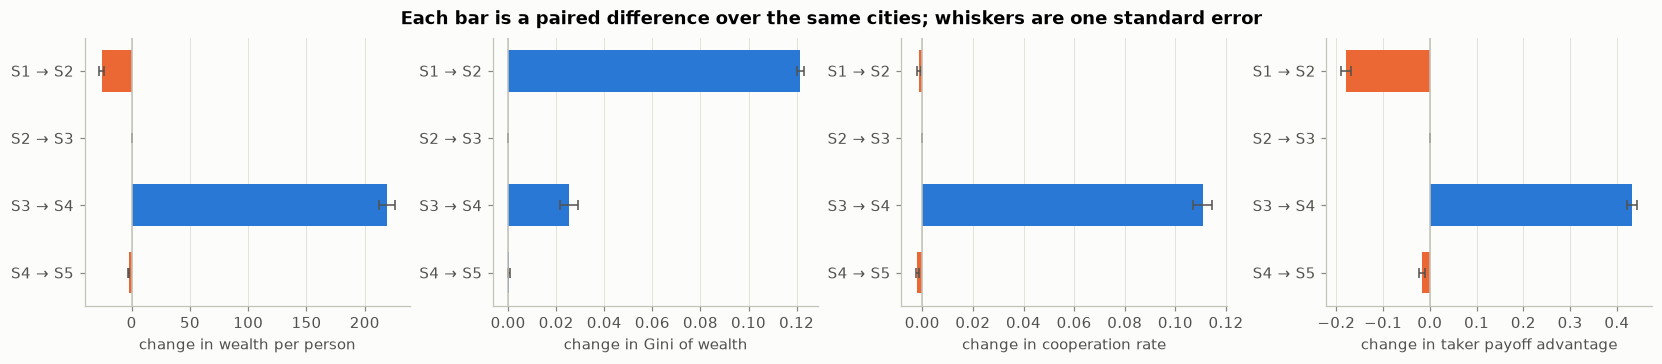

,metric,step,mean,se,n
0,mean_wealth,S1 → S2,-25.5700,2.0268,240
1,mean_wealth,S2 → S3,0.0000,0.0000,240
2,mean_wealth,S3 → S4,219.1714,7.0787,240
3,mean_wealth,S4 → S5,-2.6478,0.6806,240
0,gini,S1 → S2,0.1216,0.0014,240
1,gini,S2 → S3,0.0000,0.0000,240
2,gini,S3 → S4,0.0252,0.0037,240
3,gini,S4 → S5,0.0004,0.0005,240
0,coop_rate,S1 → S2,-0.0013,0.0008,240
1,coop_rate,S2 → S3,0.0000,0.0000,240


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
panels = [("mean_wealth", "change in wealth per person"), ("gini", "change in Gini of wealth"),
          ("coop_rate", "change in cooperation rate"), ("payoff_gap", "change in taker payoff advantage")]
deltas = {}
# payoff_gap is undefined when a class is absent, so its panel pairs 32 cities rather than 48.
for ax, (metric, label) in zip(axes, panels):
    deltas[metric] = R.stage_deltas(runs, metric, LADDER)
    P.delta_bars(ax, deltas[metric], xlabel=label)
fig.suptitle("Each bar is a paired difference over the same cities; whiskers are one standard error",
             fontweight="bold")
plt.show()

pd.concat([t.assign(metric=m) for m, t in deltas.items()])[["metric", "step", "mean", "se", "n"]].round(4)

**What this shows, and where it revises the story above:**

- **Structure redistributes without creating.** Putting the same population on a fixed network
  (S1 to S2) raises the Gini by 0.122 and *lowers* wealth per person slightly (-25.6). The taker
  payoff advantage does fall, by 0.179 per game, which is network reciprocity working as expected.
  But the cooperation rate barely moves: -0.0013, with a standard error of 0.0008. The
  results section above reads this step as reciprocal strategies punishing takers, and that is
  right about *who wins*; it is wrong to imply the city becomes more cooperative. It does not.
  Network reciprocity here changes the distribution of a fixed amount of cooperation.

- **Choice is where almost everything happens.** S3 to S4 adds +219 to wealth per person, +0.111
  to the cooperation rate, +0.025 to the Gini and -0.103 to class assortativity. Every headline
  result in this project is produced by this one step. It also *reverses* the taker payoff
  advantage, adding back 0.433 per game. The reason is below: choice does not change how a
  taker plays, it changes who it plays.

- **S2 to S3 is exactly zero on every measure in this table.** Not approximately: the paired
  difference and its standard error are both 0.0000, because no tie in any S3 city ever decays
  past the severance threshold. The two cities hold an identical set of ties from the first week
  to the last, and 46 of the 52 numbers recorded per run come back exactly the same.

  The other six are the ones that matter for what follows. Fading leaves the *set* of ties alone
  but not their **strength**: mean tie strength is 159 lower in S3 (paired difference -158.95,
  standard error 0.54), because S2's strengths accumulate without limit while S3's are pulled back
  every week. Weighted community structure follows, moving modularity by +0.018 and adding about
  a third of a community. So decay is not a mechanism that does nothing; it is one that does nothing
  **yet**. Tie strength is exactly what the choice rule weighs when it picks a partner, so S3 is
  the step that gives S4 something to read.

- **Rewiring repairs rather than redistributes.** S4 to S5 moves wealth by -2.6 and the Gini by
  +0.0004, neither distinguishable from zero, while it returns +0.072 of class assortativity, a
  little over half of what the previous step removed.

In [11]:
# Choice does not change how a taker plays; it changes who it plays. Every citizen weighs
# candidates by the partner's rating, and givers are the ones with high ratings.
def partner_mix_once(stage_name, repeat):
    cfg = stage(stage_name, **{**SETTINGS, "population.giver_fraction": 0.5})
    sim = Simulation(cfg, root_seed=R.DEFAULT_SEED, repeat=repeat, instruments=("core",))
    giver = sim.state.giver
    played = np.zeros((2, 2))                              # [actor is a giver, partner is a giver]
    for _ in range(cfg.run.n_rounds):
        record = sim.run_round().record
        if record.n_games == 0:
            continue
        gi, gj = giver[record.initiator], giver[record.partner]
        for actor, partner in ((gi, gj), (gj, gi)):        # both sides of every game
            for cls in (0, 1):
                played[cls, 1] += ((actor == bool(cls)) & partner).sum()
                played[cls, 0] += ((actor == bool(cls)) & ~partner).sum()
    share = played / played.sum(axis=1, keepdims=True)
    return {"a taker's games that are against givers": share[0, 1],
            "a giver's games that are against givers": share[1, 1],
            "mean popularity rating, givers": sim.state.rating[giver].mean(),
            "mean popularity rating, takers": sim.state.rating[~giver].mean()}


# The same seeds as the sweep, so these numbers carry their uncertainty like the rest.
def partner_mix(stage_name, n_seeds=N_SEEDS):
    seeds = pd.DataFrame([partner_mix_once(stage_name, repeat) for repeat in range(n_seeds)])
    return pd.DataFrame({"mean": seeds.mean(), "se": seeds.sem()})

mix = pd.concat({"S3 uniform draws": partner_mix("M2"),
                 "S4 chosen partners": partner_mix("M3")}, axis=1)
mix.round(3)

S3 uniform draws         \
                                                    mean     se   
a taker's games that are against givers            0.499  0.005   
a giver's games that are against givers            0.495  0.006   
mean popularity rating, givers                     1.000  0.000   
mean popularity rating, takers                     1.000  0.000   

                                        S4 chosen partners         
                                                      mean     se  
a taker's games that are against givers              0.767  0.006  
a giver's games that are against givers              0.585  0.003  
mean popularity rating, givers                       0.507  0.002  
mean popularity rating, takers                       0.168  0.001

**Who a taker gets to play:** under uniform draws both classes face the mix you would expect by
chance, near 50/50 (a taker 0.499, a giver 0.495). Once meetings are chosen, a taker plays **77%**
of its games against givers, while a giver plays 59% of its games against other givers. Nobody
wrote a rule sending takers towards cooperators: every citizen weighs candidates by the partner's
rating, givers earn ratings three times higher than takers (0.507 against 0.168), and so everyone
steers the same way. Takers steer there too, and **givers cannot refuse**: a giver has no means
of declining a partner that defected on it last week, only of defecting back. All figures are
means over the same 40 seeds as the sweep, and the standard errors are in the table.

Defecting on a cooperator pays `T = 5`, the largest payoff in the game, so a diet three-quarters
made of cooperators is what lifts the taker payoff advantage by 0.433 at this step.

Both classes still *initiate* half the meetings, because every citizen starts exactly one per week.
The asymmetry is not in who reaches out; it is in who they reach for, and in who has to accept.
This is also the mechanism behind the negative class assortativity reported above, and the reason
the right to refuse is the first item in the future work below.

### Clustering and Connectivity

H2 argues that inequality does not fall with cooperation partly because "cooperation relies on
clusters". Up to this point that claim was carried entirely by the citations: no measurement in
this notebook said anything about clustering. Two coefficients fix that.

**Average clustering** is the mean over citizens of the share of their acquaintance pairs who
also know each other, so it reports the typical citizen. **Transitivity** is closed triples over
all triples across the whole city, which weights by degree and so reports the city. Both are
tracked every 10 weeks alongside the mean shortest path and the number of components.

One caution has to come before any number. The claim in the literature is **evolutionary**:
cooperators who cluster shield one another from defectors, do better on average, and are then
imitated or reproduced, so cooperation spreads. Our citizens are assigned a strategy in week 0
and never change it, and nobody ever copies anyone. That mechanism cannot run in this model at
all, so nothing measured here can confirm or refute H2's premise on its own terms.

It also means a correlation between clustering and cooperation *across the sweep* would be
worthless as evidence. The sweep varies the giver fraction, and the giver fraction sets the
cooperation rate almost by itself; pooling cities with different mixes would mostly measure the
population, not the wiring. What the model can answer is the narrower question: holding the
population fixed, does the **arrangement** of the same ties matter? That has a clean test, and
it is run below.

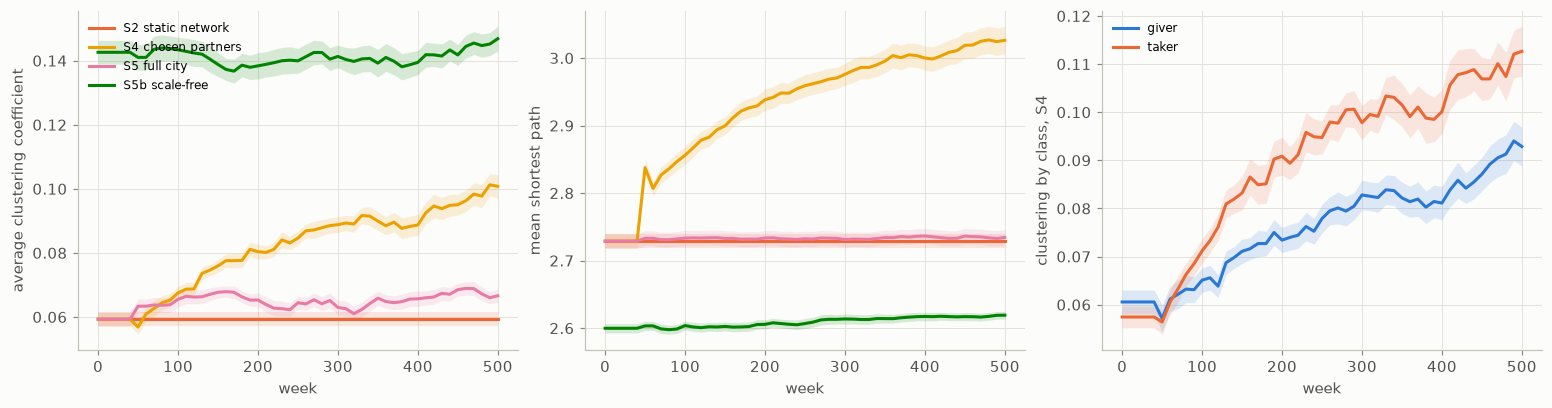

clustering        mean_path_length        n_components  \
round                     0      500              0      500          0     
scenario                                                                    
S1 well-mixed           1.000  1.000            1.000  1.000          1.0   
S2 static network       0.059  0.059            2.729  2.729          1.0   
S3 ties fade            0.059  0.059            2.729  2.729          1.0   
S4 chosen partners      0.059  0.101            2.729  3.026          1.0   
S5 full city            0.059  0.067            2.729  2.734          1.0   
S5b scale-free          0.143  0.147            2.600  2.619          1.0   

                          
round                500  
scenario                  
S1 well-mixed       1.00  
S2 static network   1.00  
S3 ties fade        1.00  
S4 chosen partners  1.15  
S5 full city        1.00  
S5b scale-free      1.00

In [12]:
mid_structure = sweep.structure[np.isclose(sweep.structure["giver_fraction"], 0.6)]
structure_ts = R.series_means(mid_structure, ["clustering", "clustering_giver", "clustering_taker",
                                              "transitivity", "mean_path_length", "n_components"])
NETWORKS = ["S2 static network", "S4 chosen partners", "S5 full city", "S5b scale-free"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
P.over_time(axes[0], structure_ts, "clustering", NETWORKS, colours,
            ylabel="average clustering coefficient")
P.over_time(axes[1], structure_ts, "mean_path_length", NETWORKS, colours,
            ylabel="mean shortest path")
s4 = structure_ts[structure_ts["scenario"] == "S4 chosen partners"].sort_values("round")
for column, label in [("clustering_giver", "giver"), ("clustering_taker", "taker")]:
    P.band(axes[2], s4["round"], s4[column], s4[column] - s4[f"{column}_se"],
           s4[column] + s4[f"{column}_se"], P.CLASS_COLOURS[label], label=label)
axes[2].set(xlabel="week", ylabel="clustering by class, S4")
axes[0].legend(fontsize=8, loc="upper left")
axes[2].legend(fontsize=8)
plt.show()

# The path length is reported next to the component count deliberately. It averages only over
# pairs that can still reach each other, so a city that breaks apart can post a *shorter* mean
# path simply by dropping its longest routes from the average. The two have to be read together.
edges = structure_ts[structure_ts["round"].isin([0, structure_ts["round"].max()])]
edges.pivot_table(index="scenario", columns="round",
                  values=["clustering", "mean_path_length", "n_components"]).round(3)

**A real test: turning clustering up and down directly.** The Watts-Strogatz model interpolates
between a ring lattice and a random graph with one rewiring probability `p`, holding the mean
degree at 6 the whole way. At `p = 0` every citizen sits in a tight neighbourhood and clustering
is 0.60; at `p = 1` the wiring is essentially random and clustering is 0.05. Running the same
population across that dial separates the arrangement of ties from the mix of people, which is
exactly what the sweep could not do.

The test has to be run on **S2**, the static network, because that is the only scenario where the
setting survives. In S4 and S5 the city rewrites its own ties, and by week 500 a lattice that
started at 0.60 ends at 0.089, while one that started at 0.053 ends at 0.058: the eleven-fold
gap it was handed is compressed to a difference of 0.03, about 94% of it erased.
That is worth knowing on its own: in the full model the city's tie dynamics overwrite whatever
clustering it was handed, so clustering there is an outcome rather than a condition.

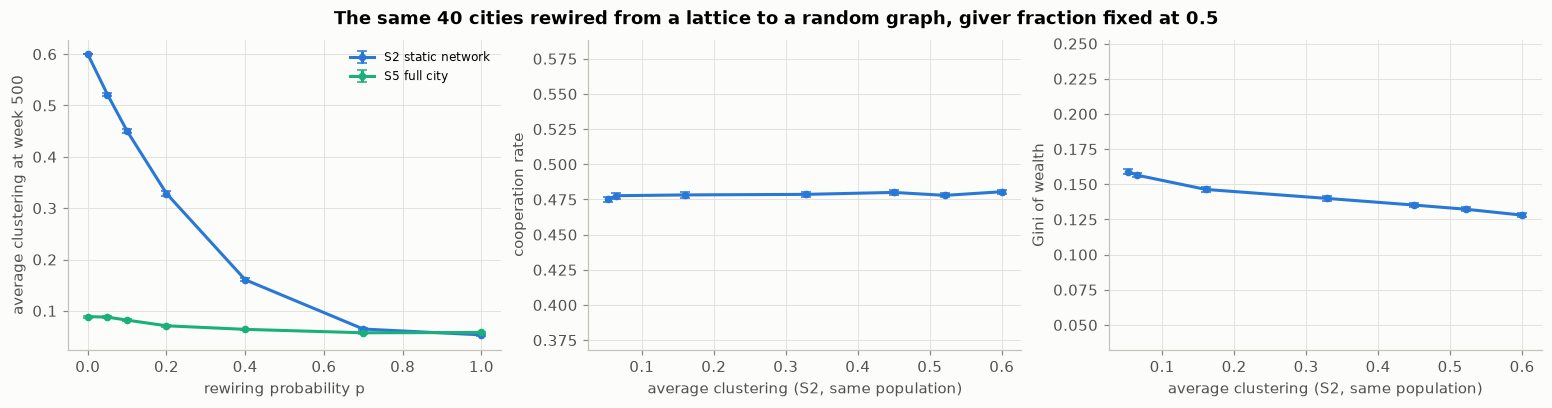

,lattice (p = 0),random (p = 1),paired change,se
metric,,,,
clustering,0.6000,0.0532,-0.5468,0.0014
coop_rate,0.4805,0.4750,-0.0055,0.0025
gini,0.1281,0.1589,0.0309,0.0023


In [13]:
# One population, one mean degree, one giver fraction: only the arrangement of ties changes.
REWIRE = [0.0, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
WS_SCENARIOS = {f"{label}|{p}": (base, {"topology.name": "watts_strogatz",
                                        "topology.ws_rewire_prob": p})
                for label, base in [("S2 static network", "M1"), ("S5 full city", "M4")]
                for p in REWIRE}
ws = R.sweep(WS_SCENARIOS, [0.5], n_seeds=N_SEEDS, **SETTINGS)
ws["stage"] = ws["scenario"].str.split("|").str[0]
ws["rewire"] = ws["scenario"].str.split("|").str[1].astype(float)
dial = R.cell_means(ws, ["clustering", "coop_rate", "gini"], by=("stage", "rewire"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for stage_label, colour in zip(["S2 static network", "S5 full city"], [P.SERIES[0], P.SERIES[2]]):
    rows = dial[dial["stage"] == stage_label].sort_values("rewire")
    axes[0].errorbar(rows["rewire"], rows["clustering"], yerr=rows["clustering_se"],
                     color=colour, marker="o", markersize=4, capsize=3, label=stage_label)
axes[0].set(xlabel="rewiring probability p", ylabel="average clustering at week 500")
axes[0].legend(fontsize=8)

static = dial[dial["stage"] == "S2 static network"].sort_values("clustering")
# The y range is set to the size of the effect that partner choice produced (+0.110 cooperation),
# so that "flat" is read against something rather than against the width of the axis.
for ax, metric, label, span in [(axes[1], "coop_rate", "cooperation rate", 0.11),
                                (axes[2], "gini", "Gini of wealth", 0.11)]:
    ax.errorbar(static["clustering"], static[metric], yerr=static[f"{metric}_se"],
                color=P.SERIES[0], marker="o", markersize=4, capsize=3)
    centre = static[metric].mean()
    ax.set(xlabel="average clustering (S2, same population)", ylabel=label,
           ylim=(centre - span, centre + span))
fig.suptitle(f"The same {N_SEEDS} cities rewired from a lattice to a random graph, giver "
             "fraction fixed at 0.5", fontweight="bold")
plt.show()

paired = ws[ws["stage"] == "S2 static network"].pivot_table(
    index="repeat", columns="rewire", values=["clustering", "coop_rate", "gini"])
pd.DataFrame([{"metric": m, "lattice (p = 0)": paired[m][0.0].mean(),
               "random (p = 1)": paired[m][1.0].mean(),
               "paired change": (paired[m][1.0] - paired[m][0.0]).mean(),
               "se": (paired[m][1.0] - paired[m][0.0]).sem()}
              for m in ["clustering", "coop_rate", "gini"]]).set_index("metric").round(4)

**What this shows:**

- **Severance concentrates, rewiring restores reach.** In S4, where ties break and are never
  replaced, clustering rises from 0.059 to 0.101 while the mean shortest path stretches from 2.73
  to 3.03 and the city splits into 1.15 components on average. Those two numbers belong in the
  same sentence: the mean path length is taken over reachable pairs only, so a fragmenting city
  can post a *shorter* path by dropping its longest routes out of the average entirely. Here the
  path grows despite that, which makes the stretching real rather than an artefact. In S5 the same
  severance happens, but refilled ties are drawn from distance 2 and 3, so clustering barely moves
  (0.059 to 0.067), the path holds at 2.73, and the city stays in exactly one piece (1.00
  components). Rewiring buys connectivity at the cost of the local concentration that severance
  was producing.

- **Clustering moves cooperation, by an amount too small to matter.** Collapsing clustering from
  0.600 to 0.053 (an eleven-fold change, with the same citizens, the same mean degree and the
  giver fraction pinned at 0.5) moves the cooperation rate by **-0.0055, with a standard error of
  0.0025**. At 40 seeds that is resolved rather than lost in noise, and its sign agrees with H2:
  the more clustered city is the more cooperative one. But the size is the finding. It is
  **twenty times smaller** than the +0.111 that partner choice delivers at a single step of the
  ladder. Within what this model can express, how ties are arranged is a rounding error next to
  who gets chosen.

  This is a narrow result and worth stating narrowly. It does not refute the literature, because
  the mechanism the literature proposes cannot occur here: no citizen ever changes strategy, so
  clustered cooperators can never out-reproduce anyone. The honest conclusion is that **H2 should
  not rest on clustering** in this project. It should rest on access and status, which the
  decomposition above does support and measure.

- **Inequality moves along the dial too, but the cause is not clean.** The same rewiring raises
  the Gini by +0.031 (se 0.002), monotonically, from 0.128 in the lattice to 0.159 in the random
  graph. The tempting reading is that clustering protects the poor. The careful one is that
  Watts-Strogatz rewires one end of each edge, so it also spreads the degrees, from exactly 6 for
  every citizen at `p = 0` to a standard deviation of 1.7 at `p = 1`. Capacity is pinned at the
  starting degree, so that spread is itself unequal access. This design cannot separate the two,
  and we do not claim it does, but both readings point the same way as the rest of the project:
  inequality tracks who can be met, not who defects.

- **Takers sit in denser neighbourhoods than givers**, in every scenario (S4: 0.113 against 0.093).
  This is very likely an artefact rather than a finding: the clustering coefficient divides by
  `k(k-1)`, and takers hold fewer ties, which mechanically raises the ratio. It should not be read
  as takers forming cliques without a degree-matched comparison, which we have not run.

### Inequality Without Exploitation

The Lorenz curves earlier showed something that deserves more than a passing note: a city where
**every** citizen plays Tit-for-Tat, and where no game is ever exploited, is almost exactly as
unequal as a mixed city. Two explanations were offered in the group: that some citizens fall into
positively reinforced relationships early, and that others become trapped in mutually punishing
ones.

The second cannot be true in a TFT-only city. Tit-for-Tat opens with cooperation and mirrors
afterwards, so two TFT agents cooperate forever and never defect once. There are no punishing
relationships to fall into. That turns out to make the test sharper rather than spoiling it: if
every move is cooperative, then each game pays exactly `R = 3` to both players, and

$$ \text{wealth}_i = 3 \times \text{games played}_i $$

exactly. Inequality of wealth *is* inequality of attention, with nothing else mixed in. So we can
ask where the attention goes by switching off the two feedback channels in the choice rule, one at
a time: habit ($\beta$, the weight on an existing tie) and status ($\gamma$, the weight on the
partner's rating).

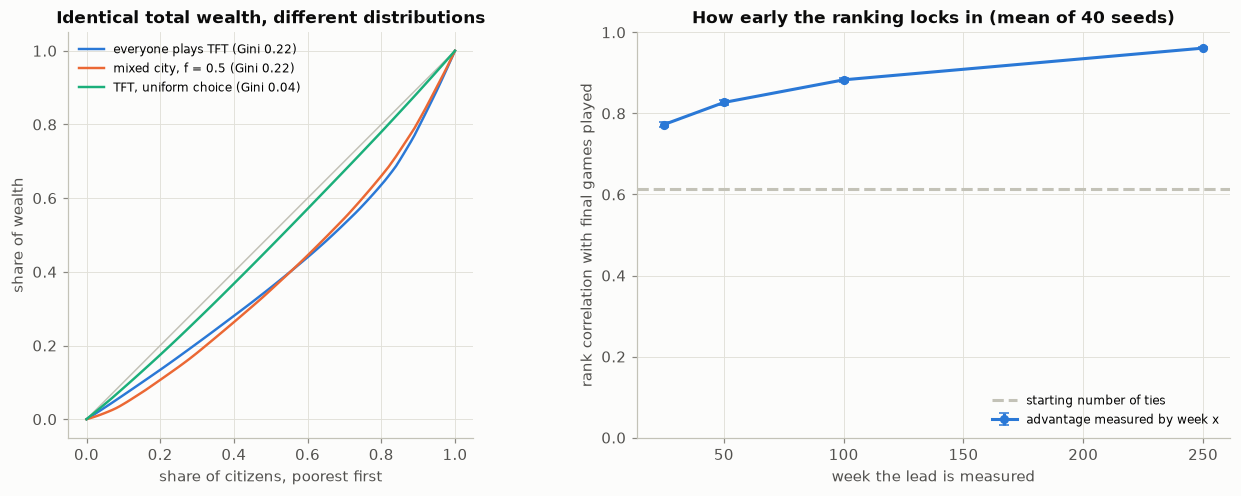

every move cooperative, so wealth is exactly three times games played: True
lock-in, mean of 40 seeds (se in brackets): week 25 0.77 (0.01), week 50 0.83 (0.01), week 100 0.88 (0.00), week 250 0.96 (0.00) | starting ties 0.61 (0.01)
TFT-only Gini 0.206 | mixed city Gini 0.231 (se 0.002, 40 seeds each)


,scenario,gini,mean_wealth,gini_se,mean_wealth_se
0,full: habit x status,0.2059,3000.0,0.0015,0.0
1,habit only,0.0504,3000.0,0.0010,0.0
2,neither: uniform,0.0513,3000.0,0.0012,0.0
3,status only,0.1319,3000.0,0.0014,0.0


In [14]:
CHOICE_VARIANTS = {
    "full: habit x status": ("M4", {}),
    "status only":          ("M4", {"encounter.weight_exponent": 0.0}),
    "habit only":           ("M4", {"encounter.popularity_exponent": 0.0}),
    "neither: uniform":     ("M4", {"encounter.weight_exponent": 0.0, "encounter.popularity_exponent": 0.0}),
}
ALL_TFT = {"population.giver_composition": {"tft": 1.0}}
tft_runs = R.sweep(CHOICE_VARIANTS, [1.0], n_seeds=N_SEEDS, **{**SETTINGS, **ALL_TFT})
decomposition = R.cell_means(tft_runs, ["gini", "mean_wealth"], by=("scenario",))

# The mixed city on the same seeds, so the two Ginis compared in the text are the same kind of
# number: a mean over runs, not one city against an average.
mixed_reference = R.sweep({"mixed city, f = 0.5": ("M4", {})}, [0.5], n_seeds=N_SEEDS, **SETTINGS)

curves, curve_ginis = {}, {}
for label, overrides in [("everyone plays TFT", {**ALL_TFT, "population.giver_fraction": 1.0}),
                         ("mixed city, f = 0.5", {"population.giver_fraction": 0.5}),
                         ("TFT, uniform choice", {**ALL_TFT, "population.giver_fraction": 1.0,
                                                  "encounter.weight_exponent": 0.0,
                                                  "encounter.popularity_exponent": 0.0})]:
    sim = Simulation(stage("M4", **{**SETTINGS, **overrides}), root_seed=R.DEFAULT_SEED,
                     repeat=0, instruments=("core",))
    sim.run()
    curves[label], curve_ginis[label] = metrics.lorenz(sim.state.wealth), metrics.gini(sim.state.wealth)

# Does an early lead survive? Rank citizens by games played at several points, against the end.
# Averaged over the same seeds as everything else, rather than read off one city.
MARKS = [25, 50, 100, 250]
lock_rows = []
for repeat in range(N_SEEDS):
    watch = Simulation(stage("M4", **{**SETTINGS, **ALL_TFT, "population.giver_fraction": 1.0}),
                       root_seed=R.DEFAULT_SEED, repeat=repeat, instruments=("core",))
    marks = {}
    for _ in range(SETTINGS["run.n_rounds"]):
        watch.run_round()
        if watch.state.t in MARKS:
            marks[watch.state.t] = watch.state.games_played.copy()
    final_games = watch.state.games_played
    lock_rows.append({**{week: metrics.spearman(marks[week], final_games) for week in MARKS},
                      "starting ties": metrics.spearman(watch.state.capacity, final_games),
                      "wealth is exactly 3x games": np.allclose(watch.state.wealth, 3.0 * final_games)})
lock = pd.DataFrame(lock_rows)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
P.lorenz_curves(axes[0], curves, ginis=curve_ginis)
axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("Identical total wealth, different distributions")
axes[1].errorbar(MARKS, lock[MARKS].mean(), yerr=lock[MARKS].sem(), color=P.SERIES[0],
                 marker="o", capsize=3, label="advantage measured by week x")
axes[1].axhline(lock["starting ties"].mean(), color=P.AXIS, linestyle="--",
                label="starting number of ties")
axes[1].set(xlabel="week the lead is measured", ylabel="rank correlation with final games played",
            ylim=(0, 1), title=f"How early the ranking locks in (mean of {N_SEEDS} seeds)")
axes[1].legend(fontsize=8, loc="lower right")
plt.show()

print(f"every move cooperative, so wealth is exactly three times games played: "
      f"{lock['wealth is exactly 3x games'].all()}")
print(f"lock-in, mean of {N_SEEDS} seeds (se in brackets): "
      + ", ".join(f"week {w} {lock[w].mean():.2f} ({lock[w].sem():.2f})" for w in MARKS)
      + f" | starting ties {lock['starting ties'].mean():.2f} ({lock['starting ties'].sem():.2f})")
print(f"TFT-only Gini {decomposition.set_index('scenario').loc['full: habit x status', 'gini']:.3f} "
      f"| mixed city Gini {mixed_reference['gini'].mean():.3f} "
      f"(se {mixed_reference['gini'].sem():.3f}, {N_SEEDS} seeds each)")
decomposition.round(4)

**What this shows:**

| Partner choice, everyone plays TFT | Gini | Wealth per person |
|---|---|---|
| Full: habit x status | 0.206 | 3,000 |
| Status only | 0.132 | 3,000 |
| Habit only | 0.050 | 3,000 |
| Neither: uniform | 0.051 | 3,000 |

**Wealth per person is identical to the unit in all four.** The *city* plays the same number of
games in total whatever the choice rule is, and every game pays 3 to each side, so the total
wealth is fixed by the rules before anyone meets anyone. What varies is who those games go to,
and that alone moves the Gini from 0.051 to 0.206, a factor of four.

**Status is the whole of it.** Removing status returns inequality to the uniform baseline exactly
(0.050 against 0.051, a difference of -0.001 that the standard errors cannot distinguish from
zero); removing habit leaves most of it standing (0.132, or +0.081 over baseline). Habit on its
own contributes nothing measurable at all. Yet the two together produce +0.155 over baseline,
almost twice what status manages alone, so they compound rather than add: the rating is a product
of cooperativeness and *relative tie strength*, and habit builds the strength that status then
rewards. Habit is not a channel to inequality by itself; it is the raw material status works on.

**And the ranking locks in early.** Averaged over the same 40 seeds, the rank correlation between
games played by week 25 and games played at week 500 is +0.77, rising to +0.96 by week 250. A
citizen's starting number of ties predicts the final count at +0.61 on its own. So the answer to
the original question is: yes, some citizens do get into positively reinforced relationships
early, and the advantage is close to permanent by the time the city is a tenth of the way through
its life. No exploitation is required, and none occurs.

This is the sharpest statement of the project's central conclusion. A TFT-only city reaches a
Gini of 0.206 and a mixed city 0.231, both means over 40 seeds: nearly the same inequality from
completely different moral material. **Inequality here is positional, not extractive.** The
Lorenz curve of a city where nobody can be cheated looks like the Lorenz curve of one where half
the population cheats, because in both the binding constraint is who gets met.

### Example Cities

Everything above is an average over seeds. This last figure is not evidence and is not used to
support any claim; it is here to show what the mechanisms look like on a single small city, at a
size where individual citizens can be picked out.

The top row follows one 40-citizen city through its life. The bottom row shows four different
seeds at the same final week, which is the honest caveat: at this size the structure is noisy, and
any one picture would mislead if read as typical.

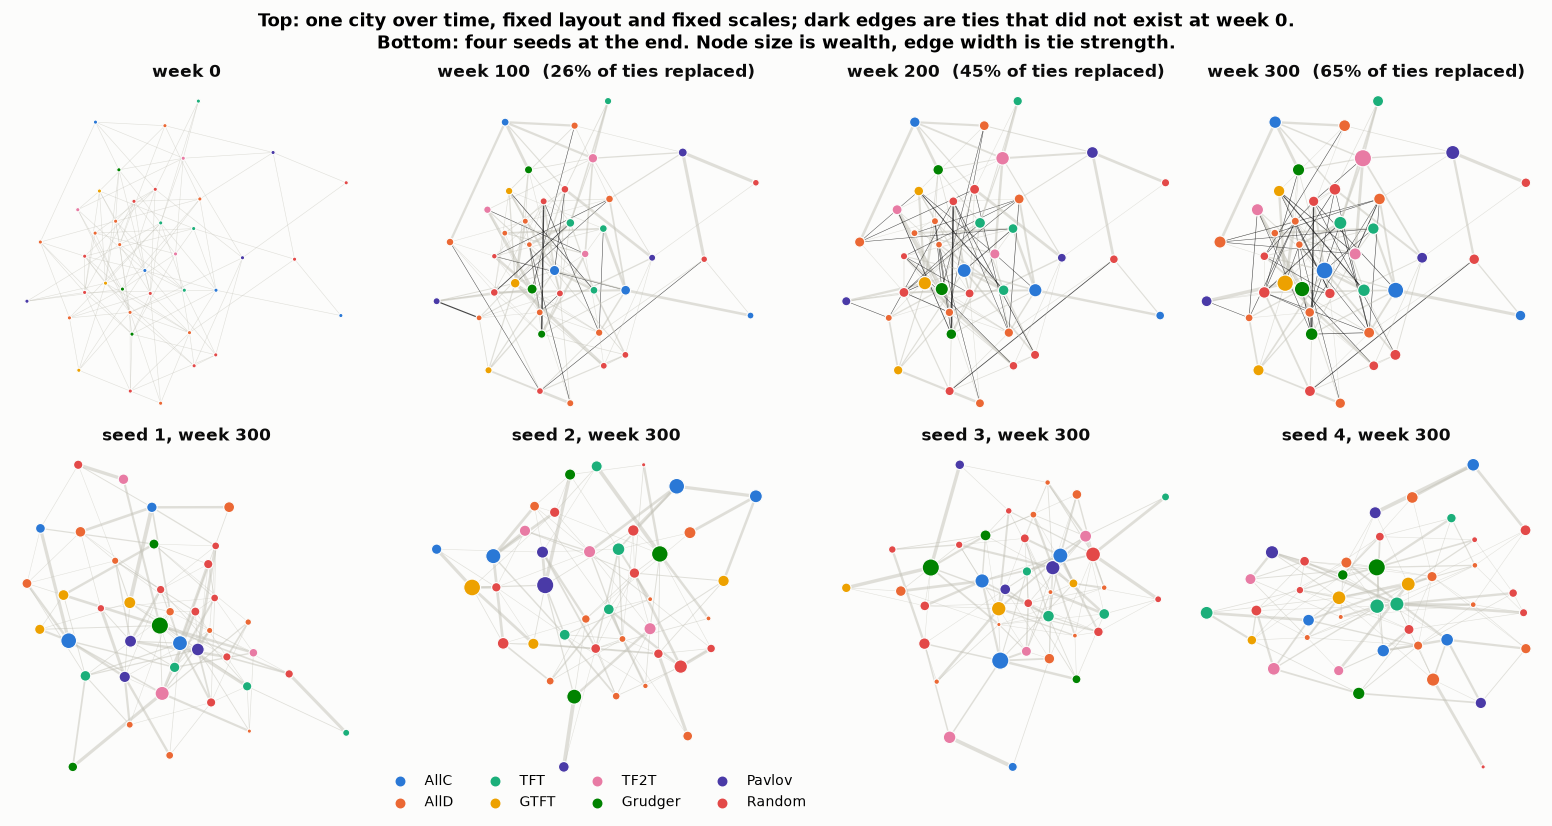

In [15]:
from utilities.network_draw import draw_snapshot, layout, strategy_legend

DEMO = {"population.n_agents": 40, "run.n_rounds": 300, "population.giver_fraction": 0.5}
demo = Simulation(stage("M4", **DEMO), root_seed=R.DEFAULT_SEED, repeat=0, instruments=("snapshots",))
frames = {frame["round"]: frame for frame in demo.run().outputs["snapshots"]}
pos = layout(frames[0]["adjacency"], seed=3)      # fixed positions, so ties can be seen moving
start = frames[0]["adjacency"]

# Fixed scales across the row. Left to normalise per panel, a city that is churning heavily
# still looks unchanged, because every frame rescales to its own richest citizen.
shown = [0, 100, 200, 300]
wealth_scale = (0.0, max(frames[w]["wealth"].max() for w in shown))
weight_scale = max(frames[w]["weight"].max() for w in shown)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.4))
for ax, week in zip(axes[0], shown):
    churn = np.triu(frames[week]["adjacency"] ^ start, 1).sum() / np.triu(start, 1).sum()
    draw_snapshot(ax, frames[week], pos, since=start, wealth_scale=wealth_scale,
                  weight_scale=weight_scale,
                  title=f"week {week}" + (f"  ({churn:.0%} of ties replaced)" if week else ""))
for ax, repeat in zip(axes[1], range(1, 5)):
    other = Simulation(stage("M4", **DEMO), root_seed=R.DEFAULT_SEED, repeat=repeat,
                       instruments=("snapshot",))
    snap = other.run().outputs["snapshot"]
    draw_snapshot(ax, snap, layout(snap["adjacency"], seed=3), title=f"seed {repeat}, week 300")
strategy_legend(axes[1][1])
fig.suptitle("Top: one city over time, fixed layout and fixed scales; dark edges are ties that "
             "did not exist at week 0.\nBottom: four seeds at the end. "
             "Node size is wealth, edge width is tie strength.", fontweight="bold")
plt.show()


**What to look for:** node size is accumulated wealth and edge width is tie strength, so the top
row shows a city that starts uniform and ends with a handful of thick, heavily used relationships
and a periphery of thin ones. The takers (orange, red) are not pushed to the edge of the drawing,
which is the point made in the results: they keep their ties to givers, and it is the ties
*between* takers that fade.

The bottom row is the reason this is illustrative only. Four cities under identical rules, and
the eye finds a different story in each.

## Conclusions

- **More givers make a city richer, and the gain accelerates:** prosperity is set by how often givers meet each other, not by how many there are, so wealth per person bends upwards once givers pass about 30% of the city.

- **Prosperity and equality come apart:** inequality peaks in mixed cities rather than falling steadily as cooperation rises. On a scale-free network it stays high in the richest cities, because hubs capture the surplus. This runs against network-game results that report inequality falling with cooperation [4], and it does so through a mechanism those models do not have: who you can meet.

- **Inequality here is positional, not extractive:** a city where every citizen plays Tit-for-Tat, and where no game is ever exploited, reaches a Gini of 0.206 against a mixed city's 0.231. Total wealth is identical however partners are chosen; only its distribution moves, and removing the status term from the choice rule collapses the Gini to 0.05. The rank order of who gets met is settled by week 25 and effectively fixed by week 250.

- **The clustering premise behind H2 carries almost no weight here:** rewiring a city from a lattice to a random graph, which collapses clustering elevenfold while holding the population and the mean degree fixed, changes the cooperation rate by -0.0055 (se 0.0025), some twenty times less than partner choice moves it in a single step. The effect is real and points the way H2 expects, and it is far too small to carry the hypothesis. Note also that the mechanism the literature proposes, clustered cooperators out-reproducing defectors, cannot arise in a model where nobody ever changes strategy, so this is a statement about our design and not a refutation of theirs. The case for H2 rests on access and status, which the decomposition does support.

- **Structure, not strategy, decides the distribution:** the same population produces near-equality when well-mixed and marked inequality once meetings are constrained by network, habit and status. Each restriction on access raises inequality; none of them changes anybody's strategy.

- **Segregation emerges, but not the kind we predicted:** takers end up with fewer partners and weaker ties without any rule that excludes them. Yet the city becomes *disassortative*: takers keep seeking out givers, who cannot refuse, while ties between takers fade from disuse.

- **Poor cities are equally poor:** taker-dominated cities have low median wealth and low inequality (median wealth gap -576, Gini gap -0.060), and the giver share explains more of the variation in median wealth than in inequality. Median wealth separates a good city from a bad one better than a Gini coefficient does. This is H4, and it is supported.

## Limitations and Future Work

### Limitations

- **Forty seeds and 100 agents:** enough to decide H1 and H4 and to resolve effects of about 0.005 in the cooperation rate, but small cities still have noisier structure than large ones, and every result here is a statement about a city of 100. Raising the count from 8 to 40 changed exactly one verdict, H4, by tightening the interval on its last criterion; H2 and H3 remain undecided for reasons of substance rather than sample size, and more seeds will not settle them.
- **Fixed strategies:** nobody learns, imitates a richer neighbour, or changes class. The mix is an input, not an outcome.
- **No refusal and no memory of reputation beyond one number:** a giver cannot decline a known defector. The disassortative networks depend on this.

- **The exploiters are maximally detectable:** the only takers are AllD, which never cooperates, and Random, which cooperates half the time and is barely an exploiter at all, so a city at `f = 0` still cooperates about a quarter of the time. AllD drives its own popularity rating to the floor within a few weeks, which is precisely what produces the separation reported above. A defector that cooperated most of the time would hold a respectable rating while still extracting surplus, and the reputation signal that carries most of this model has never been tested against one. The six-to-two split is itself lopsided: the giver class spans naive, unforgiving and adaptive behaviour, and the taker class spans nothing comparable.
- **Wealth only accumulates:** there is no spending, investment, inheritance or subsistence cost in these runs, so accumulated wealth keeps growing and its Gini is measured on a stock that never resets.
- **Closed cities:** no birth, death or migration, and every city starts from one generated network per seed.

### Future work

1. **Let strategies spread:** allow agents to imitate more successful neighbours. The interesting question is whether a city that starts above the prosperity threshold pulls itself up, and whether an unequal but rich city is stable.
2. **Give citizens the right to refuse:** allowing a giver to decline a known defector is the single change most likely to turn the disassortative network assortative, and it would test whether H3 fails because of the mechanism or because of this one missing rule.
3. **Spend the wealth:** a subsistence cost and an investment channel would make poverty absorbing rather than merely slow, which is closer to the phenomenon the model is aimed at.
4. **Calibrate against data:** cross-class connectedness and mobility have been measured at scale [2]; matching the model's tie distribution and mobility to that data would turn the qualitative comparisons here into quantitative ones.

## References

[1] X. Xue, W. R. Reed, and R. C. M. van Aert, "Social capital and economic growth: A meta-analysis," *Journal of Economic Surveys*, vol. 39, pp. 1395-1432, Sep. 2025, doi: 10.1111/joes.12660.

[2] R. Chetty et al., "Social capital I: Measurement and associations with economic mobility," *Nature*, vol. 608, no. 7921, pp. 108-121, Aug. 2022, doi: 10.1038/s41586-022-04996-4.

[3] A. B. Downey, *Think Complexity: Complexity Science and Computational Modeling*, 2nd ed. Sebastopol, CA, USA: O'Reilly Media, 2018.

[4] L.-L. Jiang, Y.-M. Li, W.-J. Li, and A. Szolnoki, "Combined effect of incentives and coupling in multigames in two-layer networks," *Journal of Physics: Complexity*, vol. 6, no. 1, Art. no. 015003, Mar. 2025, doi: 10.1088/2632-072X/ada844.

[5] M. Tsvetkova, "The effects of reputation on inequality in network cooperation games," *Philosophical Transactions of the Royal Society B*, vol. 376, no. 1838, Art. no. 20200299, Nov. 2021, doi: 10.1098/rstb.2020.0299.

[6] M. Tsvetkova, C. Wagner, and A. Mao, "The emergence of inequality in social groups: Network structure and institutions affect the distribution of earnings in cooperation games," *PLOS ONE*, vol. 13, no. 7, Art. no. e0200965, Jul. 2018, doi: 10.1371/journal.pone.0200965.

[7] A. Nishi, H. Shirado, D. G. Rand, and N. A. Christakis, "Inequality and visibility of wealth in experimental social networks," *Nature*, vol. 526, no. 7573, pp. 426-429, Oct. 2015, doi: 10.1038/nature15392.

[8] M. A. Nowak and R. M. May, "Evolutionary games and spatial chaos," *Nature*, vol. 359, no. 6398, pp. 826-829, Oct. 1992, doi: 10.1038/359826a0.

[9] D. Melamed, A. Harrell, and B. Simpson, "Cooperation, clustering, and assortative mixing in dynamic networks," *Proceedings of the National Academy of Sciences*, vol. 115, no. 5, pp. 951-956, Jan. 2018, doi: 10.1073/pnas.1715357115.

[10] J. Szüle, D. Kondor, L. Dobos, I. Csabai, and G. Vattay, "Lost in the city: Revisiting Milgram's experiment in the age of social networks," *PLOS ONE*, vol. 9, no. 11, Art. no. e111973, Nov. 2014, doi: 10.1371/journal.pone.0111973.

[11] W. Ahmad, M. A. Porter, and M. Beguerisse-Díaz, "Tie-decay networks in continuous time and eigenvector-based centralities," *IEEE Transactions on Network Science and Engineering*, vol. 8, no. 2, pp. 1759-1771, Apr. 2021, doi: 10.1109/TNSE.2021.3071429.

[12] V. M. R. Muggeo, "Estimating regression models with unknown break-points," *Statistics in Medicine*, vol. 22, no. 19, pp. 3055-3071, Oct. 2003, doi: 10.1002/sim.1545.

[13] A. E. Raftery, "Bayesian model selection in social research," *Sociological Methodology*, vol. 25, pp. 111-163, 1995, doi: 10.2307/271063.

[14] B. Efron, "Bootstrap methods: Another look at the jackknife," *The Annals of Statistics*, vol. 7, no. 1, pp. 1-26, Jan. 1979, doi: 10.1214/aos/1176344552.